# Experiment 5: Mutation Operation
**Aim:** To implement the mutation operation for introducing variations in individuals using Python.

**Theory:** Mutation randomly alters genes with a small probability Pm. It restores lost genetic material and maintains diversity, preventing premature convergence. Implemented: bit-flip, random-resetting (integer), Gaussian (real), swap and inversion (permutation).

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
random.seed(5); np.random.seed(5)

## 1. Bit-flip mutation

In [2]:
def bit_flip(ind, pm=0.1):
    return [1 - g if random.random() < pm else g for g in ind]

ind = [0] * 12
print("Original:", ind)
print("Mutated :", bit_flip(ind, pm=0.25))

Original: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Mutated : [0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1]


## 2. Random resetting (integer encoding)

In [3]:
def random_reset(ind, low, high, pm=0.2):
    return [random.randint(low, high) if random.random() < pm else g for g in ind]

ind = [5, 5, 5, 5, 5, 5, 5, 5]
print("Original:", ind); print("Mutated :", random_reset(ind, 1, 9, pm=0.4))

Original: [5, 5, 5, 5, 5, 5, 5, 5]
Mutated : [5, 9, 4, 4, 5, 7, 2, 8]


## 3. Gaussian mutation (real-valued encoding)

In [4]:
def gaussian(ind, pm=0.3, sigma=0.5, low=-5, high=5):
    return [min(max(g + random.gauss(0, sigma), low), high) if random.random() < pm else g for g in ind]

ind = [1.0, 2.0, 3.0, 4.0, 5.0]
print("Original:", ind); print("Mutated :", [round(g, 3) for g in gaussian(ind, pm=0.6)])

Original: [1.0, 2.0, 3.0, 4.0, 5.0]
Mutated : [2.013, 2.011, 4.008, 3.888, 5.0]


## 4. Swap mutation (permutation)

In [5]:
def swap_mutation(ind):
    ind = ind[:]
    i, j = random.sample(range(len(ind)), 2)
    ind[i], ind[j] = ind[j], ind[i]
    return ind

perm = [1, 2, 3, 4, 5, 6, 7, 8]
m = swap_mutation(perm)
print("Original:", perm); print("Mutated :", m, "valid:", sorted(m) == perm)

Original: [1, 2, 3, 4, 5, 6, 7, 8]
Mutated : [1, 4, 3, 2, 5, 6, 7, 8] valid: True


## 5. Inversion mutation (permutation)

In [6]:
def inversion(ind):
    ind = ind[:]
    i, j = sorted(random.sample(range(len(ind)), 2))
    ind[i:j + 1] = reversed(ind[i:j + 1])
    return ind

m = inversion(perm)
print("Original:", perm); print("Mutated :", m, "valid:", sorted(m) == perm)

Original: [1, 2, 3, 4, 5, 6, 7, 8]
Mutated : [1, 2, 3, 8, 7, 6, 5, 4] valid: True


## 6. Effect of the mutation rate
Average Hamming distance between a chromosome (length 100) and its mutated copy for different Pm.

Pm = 0.001  -> avg genes changed = 0.15
Pm = 0.01   -> avg genes changed = 1.06
Pm = 0.05   -> avg genes changed = 5.09
Pm = 0.1    -> avg genes changed = 9.93
Pm = 0.2    -> avg genes changed = 20.20
Pm = 0.5    -> avg genes changed = 50.16


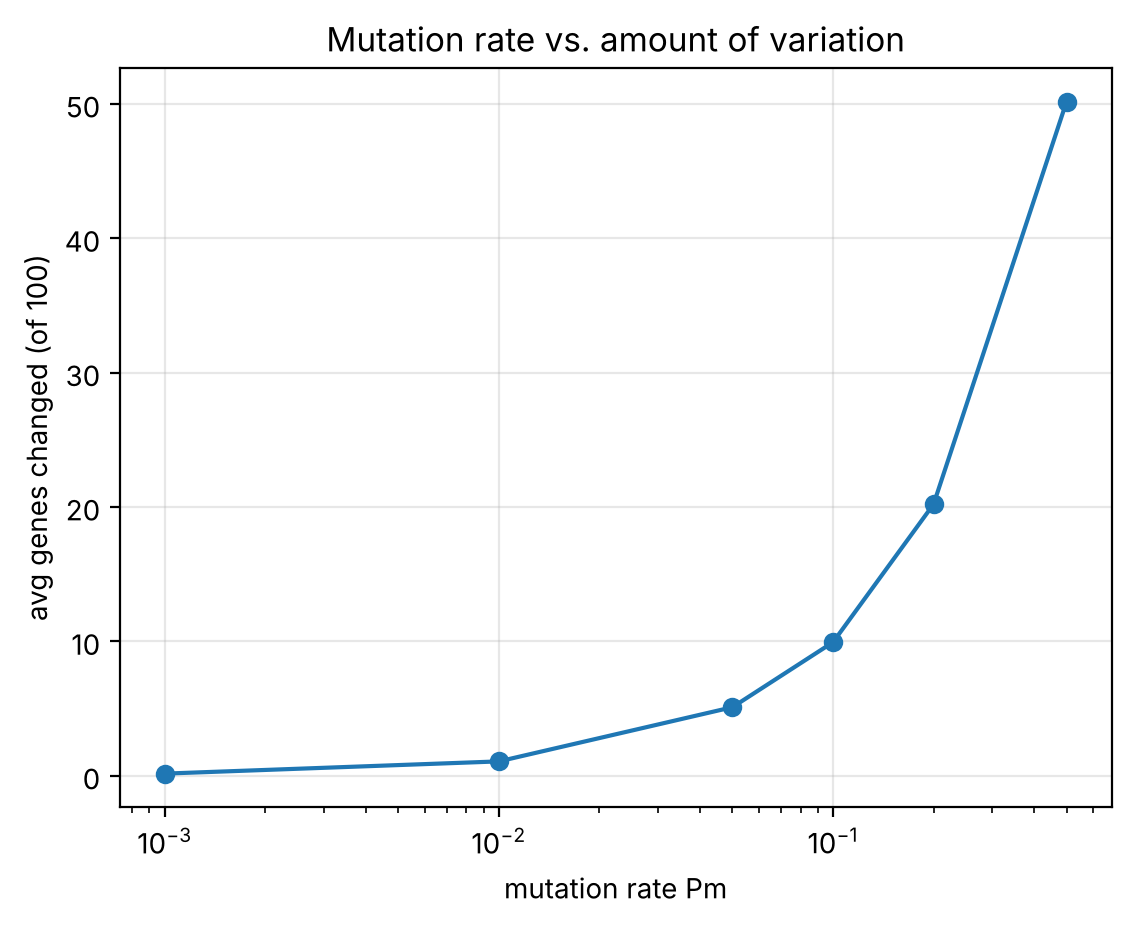

In [7]:
rates = [0.001, 0.01, 0.05, 0.1, 0.2, 0.5]
base = [0] * 100
avg_changes = []
for pm in rates:
    d = [sum(bit_flip(base, pm)) for _ in range(500)]
    avg_changes.append(np.mean(d))
    print(f"Pm = {pm:<6} -> avg genes changed = {avg_changes[-1]:.2f}")

plt.plot(rates, avg_changes, "o-")
plt.xscale("log"); plt.xlabel("mutation rate Pm"); plt.ylabel("avg genes changed (of 100)")
plt.title("Mutation rate vs. amount of variation"); plt.grid(alpha=0.3); plt.show()

## Conclusion
Bit-flip, random-resetting, Gaussian, swap and inversion mutation were implemented. The expected number of changed genes grows linearly with Pm (≈ Pm × length), so Pm must be small enough to preserve good solutions but large enough to maintain diversity.